In [1]:

import pandas as pd
import numpy as np

df = pd.read_csv('/content/train.csv')

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())


Dataset shape: (80000, 18)

Column names:
['Property_ID', 'City', 'Locality_Type', 'Property_Type', 'BHK', 'Bathrooms', 'Super_Area_SqFt', 'Carpet_Area_SqFt', 'Floor_Number', 'Total_Floors', 'Age_of_Property', 'Furnishing_Status', 'Parking', 'Lift_Available', 'Gated_Community', 'Distance_to_Metro_km', 'Distance_to_City_Center_km', 'Price_INR_Lakhs']

First 5 rows:


,Property_ID,City,Locality_Type,Property_Type,BHK,Bathrooms,Super_Area_SqFt,Carpet_Area_SqFt,Floor_Number,Total_Floors,Age_of_Property,Furnishing_Status,Parking,Lift_Available,Gated_Community,Distance_to_Metro_km,Distance_to_City_Center_km,Price_INR_Lakhs
0,PROP-005003,Chandigarh,Mid-Range,Builder Floor,4,5,1293.82,862.81,21,36,11,Semi-Furnished,1,1,1,5.34,10.84,127.38
1,PROP-009920,Kolkata,Premium,Builder Floor,2,2,2438.03,1977.23,16,31,16,Semi-Furnished,1,1,1,3.48,8.69,214.61
2,PROP-003987,Delhi,Mid-Range,Villa,3,4,1065.54,721.68,2,3,32,Semi-Furnished,0,0,1,2.66,5.73,162.56
3,PROP-084186,Chandigarh,Mid-Range,Apartment,1,2,1611.76,1327.15,38,41,27,Semi-Furnished,1,1,0,1.33,10.70,124.88
4,PROP-068764,Ahmedabad,Premium,Independent House,5,5,1043.93,781.81,21,30,23,Unfurnished,0,1,0,1.75,7.22,94.77



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 80000 entries, 0 to 79999
Data columns (total 18 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Property_ID                 80000 non-null  object 
 1   City                        80000 non-null  object 
 2   Locality_Type               80000 non-null  object 
 3   Property_Type               80000 non-null  object 
 4   BHK                         80000 non-null  int64  
 5   Bathrooms                   80000 non-null  int64  
 6   Super_Area_SqFt             80000 non-null  float64
 7   Carpet_Area_SqFt            80000 non-null  float64
 8   Floor_Number                80000 non-null  int64  
 9   Total_Floors                80000 non-null  int64  
 10  Age_of_Property             80000 non-null  int64  
 11  Furnishing_Status           80000 non-null  object 
 12  Parking                     80000 non-null  int64  
 13  Lift_Avai

Clean the dataset

In [2]:

# Remove duplicate rows
df = df.drop_duplicates().copy()

# Identify the actual target column
target = 'Price_INR_Lakhs'

if target not in df.columns:
    raise ValueError(
        f"Target '{target}' not found. Available columns: {df.columns.tolist()}"
    )

# Make sure target values are numeric
df[target] = pd.to_numeric(df[target], errors='coerce')

# Rows without a valid target cannot train a supervised model
df = df.dropna(subset=[target]).copy()

# Check missing values after cleaning
print("Shape after removing duplicates/invalid targets:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())

print("\nTarget statistics:")
display(df[target].describe())


Shape after removing duplicates/invalid targets: (80000, 18)

Missing values:
Property_ID                   0
City                          0
Locality_Type                 0
Property_Type                 0
BHK                           0
Bathrooms                     0
Super_Area_SqFt               0
Carpet_Area_SqFt              0
Floor_Number                  0
Total_Floors                  0
Age_of_Property               0
Furnishing_Status             0
Parking                       0
Lift_Available                0
Gated_Community               0
Distance_to_Metro_km          0
Distance_to_City_Center_km    0
Price_INR_Lakhs               0
dtype: int64

Target statistics:


,Price_INR_Lakhs
count,80000.000000
mean,142.612913
std,147.242507
min,2.765306
25%,54.350000
50%,96.605000
75%,176.712500
max,3334.915208


In [3]:
Perform EDA (Exploratory Data Analysis)

SyntaxError: invalid syntax (1319964286.py, line 1)

Perform EDA (Exploratory Data Analysis)


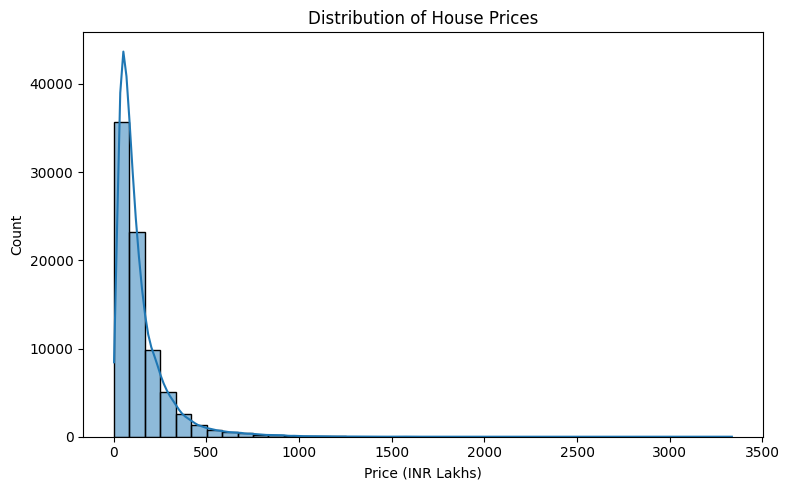

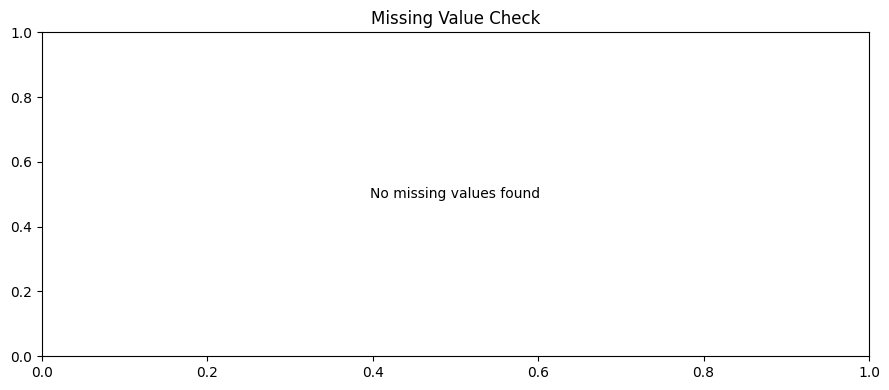

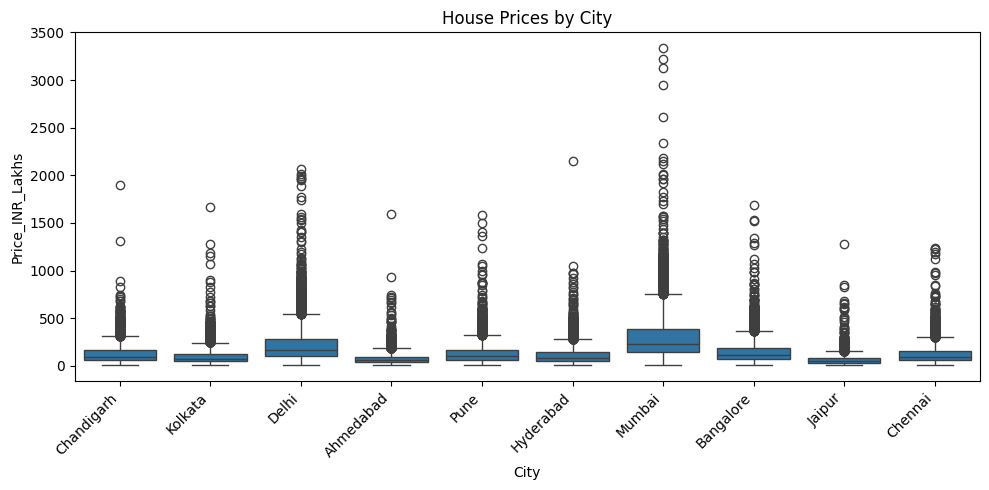

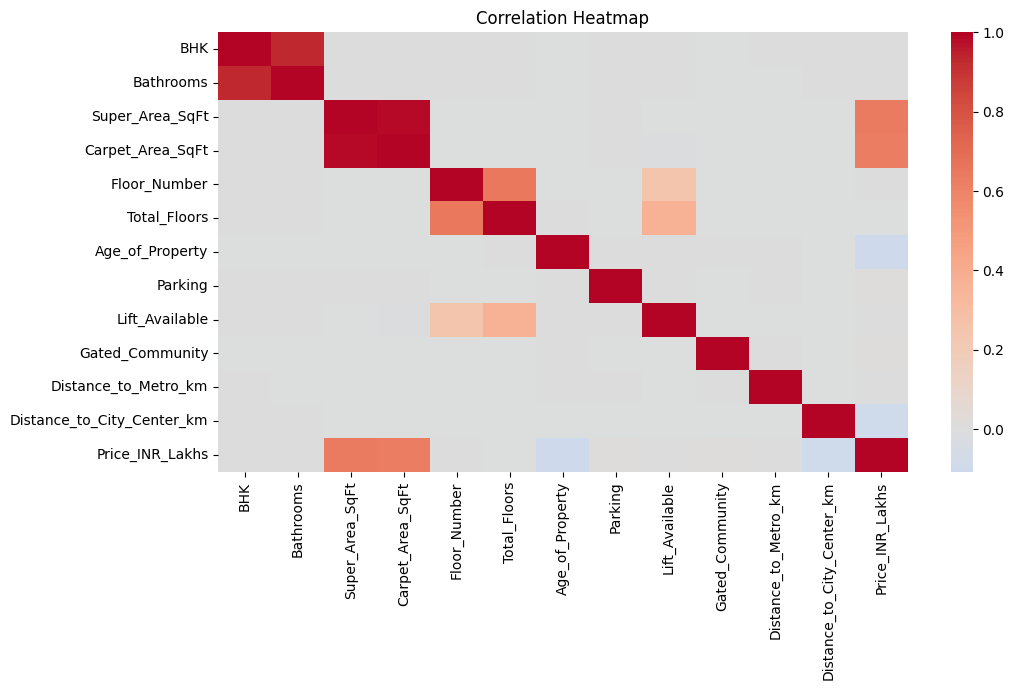

In [4]:

import matplotlib.pyplot as plt
import seaborn as sns
import os

os.makedirs('/content/housewise_outputs', exist_ok=True)

# 1. Distribution of actual house prices
plt.figure(figsize=(8, 5))
sns.histplot(df[target], bins=40, kde=True)
plt.title('Distribution of House Prices')
plt.xlabel('Price (INR Lakhs)')
plt.tight_layout()
plt.savefig('/content/housewise_outputs/price_distribution.png')
plt.show()

# 2. Missing-value chart
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

plt.figure(figsize=(9, 4))
if len(missing) > 0:
    missing.plot(kind='bar')
    plt.ylabel('Missing values')
    plt.title('Missing Values by Column')
else:
    plt.text(0.5, 0.5, 'No missing values found',
             ha='center', va='center')
    plt.title('Missing Value Check')
plt.tight_layout()
plt.savefig('/content/housewise_outputs/missing_values.png')
plt.show()

# 3. House prices by city
if 'City' in df.columns:
    plt.figure(figsize=(10, 5))
    sns.boxplot(data=df, x='City', y=target)
    plt.xticks(rotation=45, ha='right')
    plt.title('House Prices by City')
    plt.tight_layout()
    plt.savefig('/content/housewise_outputs/prices_by_city.png')
    plt.show()

# 4. Correlation between numeric features and price
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(11, 7))
sns.heatmap(numeric_df.corr(), cmap='coolwarm', center=0)
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.savefig('/content/housewise_outputs/correlation_heatmap.png')
plt.show()



Prepare the features and target


The target (y) is the actual price. The features (X) are the information used to predict it. Property_ID should not be used as a predictive feature.

In [5]:

from sklearn.model_selection import train_test_split

# Remove target and identifier from input features
drop_columns = [target]

if 'Property_ID' in df.columns:
    drop_columns.append('Property_ID')

X = df.drop(columns=drop_columns).copy()
y = df[target].copy()

# Identify numerical and categorical columns
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

# Handle any remaining missing values inside the pipeline later
print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)
print("X shape:", X.shape)
print("y shape:", y.shape)


Numerical features: ['BHK', 'Bathrooms', 'Super_Area_SqFt', 'Carpet_Area_SqFt', 'Floor_Number', 'Total_Floors', 'Age_of_Property', 'Parking', 'Lift_Available', 'Gated_Community', 'Distance_to_Metro_km', 'Distance_to_City_Center_km']
Categorical features: ['City', 'Locality_Type', 'Property_Type', 'Furnishing_Status']
X shape: (80000, 16)
y shape: (80000,)


Split the data into training and testing sets


Use an 80:20 split with random_state=42. Your teammates must use the same labelled dataset, same cleaned rows, same target and same split settings for fair model comparison.

In [6]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))


Training rows: 64000
Testing rows: 16000


Train your Linear Regression model

In [7]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib
import json

# Preprocessing for numerical features
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Preprocessing for categorical features
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer([
    ('numeric', numeric_pipeline, numeric_features),
    ('categorical', categorical_pipeline, categorical_features)
])

# Complete ML pipeline
linear_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])

# Train
linear_model.fit(X_train, y_train)

# Predict on unseen test rows
y_pred = linear_model.predict(X_test)

# Evaluate
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Linear Regression Results")
print("-------------------------")
print(f"MAE:  {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²:   {r2:.4f}")


Linear Regression Results
-------------------------
MAE:  47.9403
RMSE: 86.0255
R²:   0.6657


Save all your deliverables

In [8]:

# Save the full pipeline (preprocessing + Linear Regression)
joblib.dump(
    linear_model,
    '/content/housewise_outputs/linear_regression_model.joblib'
)

# Save metrics
metrics = {
    'Model': 'Linear Regression',
    'MAE': float(mae),
    'RMSE': float(rmse),
    'R2': float(r2),
    'Train_Rows': int(len(X_train)),
    'Test_Rows': int(len(X_test)),
    'Random_State': 42
}

pd.DataFrame([metrics]).to_csv(
    '/content/housewise_outputs/linear_regression_metrics.csv',
    index=False
)

with open('/content/housewise_outputs/linear_regression_metrics.json', 'w') as f:
    json.dump(metrics, f, indent=4)

# Save split row indices so teammates can reproduce the split
pd.DataFrame({
    'original_row_index': X_train.index,
    'split': 'train'
}).to_csv(
    '/content/housewise_outputs/train_indices.csv',
    index=False
)

pd.DataFrame({
    'original_row_index': X_test.index,
    'split': 'test'
}).to_csv(
    '/content/housewise_outputs/test_indices.csv',
    index=False
)

# Save feature schema
with open('/content/housewise_outputs/feature_schema.txt', 'w') as f:
    f.write(f'Target: {target}\n')
    f.write('Identifier excluded: Property_ID\n')
    f.write(f'Numerical features: {numeric_features}\n')
    f.write(f'Categorical features: {categorical_features}\n')
    f.write('Train/test split: 80/20\n')
    f.write('Random state: 42\n')
    f.write('Preprocessing: median imputation + standard scaling for numerical features; '
            'most-frequent imputation + one-hot encoding for categorical features.\n')

print("All files saved in /content/housewise_outputs/")


All files saved in /content/housewise_outputs/


Download the files to your laptop

In [9]:

import shutil

shutil.make_archive(
    '/content/housewise_outputs',
    'zip',
    '/content/housewise_outputs'
)

from google.colab import files
files.download('/content/housewise_outputs.zip')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [10]:

import joblib
import pandas as pd

model = joblib.load(
    '/content/housewise_outputs/linear_regression_model.joblib'
)

sample = X_test.iloc[[0]]
prediction = model.predict(sample)[0]

print("Predicted price (INR Lakhs):", round(float(prediction), 2))
print("Actual price (INR Lakhs):", round(float(y_test.iloc[0]), 2))


Predicted price (INR Lakhs): 388.52
Actual price (INR Lakhs): 333.73


In [11]:
actual = float(y_test.iloc[0])
predicted = float(prediction)

error_percentage = abs(predicted - actual) / actual * 100
print(f"Absolute percentage error: {error_percentage:.2f}%")

Absolute percentage error: 16.42%
